# PEFT vs prompting (primary model)

Compares the fine-tuned (QLoRA) Qwen models with zero-shot and five-shot prompting of the same base model.
Everything is scored by the same code (`parse_prediction` + `compute_metrics`): prompting by
`run_prompting.py`, PEFT by `rescore_predictions.py`.

1. checks (all files present, same texts, same demonstration IDs)
2. main table
3. paired bootstrap: which differences are real?
4. per-emotion F1 for all conditions
5. label counts and label distribution
6. which texts are hard for every condition
7. Swedish texts without å/ä/ö

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from llm_project.prompting import LABELS, DEFAULT_VARIANT

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((PROJECT_ROOT / "configs" / "prompting.yaml").read_text(encoding="utf-8"))

SPLIT = "test"
MODEL = cfg.get("models", [{}])[0].get("name", "Qwen2.5-3B-Instruct").split("/")[-1]
PEFT_EXPERIMENT = "baseline_qlora_qv"
ID_KEY = cfg.get("prompting", {}).get("id_key", "alignment_id")

LABELS = LABELS
CONDITIONS = {
    "zero-shot": ("prompting", "zero_shot", "default"),
    "five-shot": ("prompting", "five_shot", "default"),
    "PEFT (EN-trained)": ("peft", "peft-english", PEFT_EXPERIMENT),
    "PEFT (SV-trained)": ("peft", "peft-target", PEFT_EXPERIMENT),
    "PEFT (bilingual)": ("peft", "peft-bilingual", PEFT_EXPERIMENT),
}

PRED = PROJECT_ROOT / "outputs" / "predictions"
METRICS = PROJECT_ROOT / "outputs" / "metrics"
pd.set_option("display.precision", 3)

LANGS = ["en", cfg.get("language", "sv")]

## 1. Checks

In [2]:
from llm_project.notebook_utils import compare_predictions, load_preds, load_metrics


def run_name(lang, cond):
    family, c, v = CONDITIONS[cond]
    return family, c, v


def try_load_preds(lang, cond):
    family, c, v = run_name(lang, cond)
    path_dir = PRED / family / SPLIT
    path = path_dir / f"{MODEL}__{lang}__{c}__{v}.jsonl"
    if not path.exists():
        return None
    return load_preds(MODEL, lang, c, path_dir, variant=v).set_index(ID_KEY)


def try_load_metrics(lang, cond):
    family, c, v = run_name(lang, cond)
    path_dir = METRICS / family / SPLIT
    path = path_dir / f"{MODEL}__{lang}__{c}__{v}.json"
    return load_metrics(MODEL, lang, c, path_dir, variant=v) if path.exists() else None


available = {(l, c): try_load_preds(l, c) for l in LANGS for c in CONDITIONS}
available = {k: v for k, v in available.items() if v is not None}
print("Runs found:")
for (l, c), df in available.items():
    print(f"  {l}  {c:18s} n={len(df)}")
print(
    "Not found (expected: PEFT (SV-trained) on English):",
    [f"{l}/{c}" for l in LANGS for c in CONDITIONS if (l, c) not in available],
)

for l in LANGS:
    ids = [set(df.index) for (ll, _), df in available.items() if ll == l]
    assert all(s == ids[0] for s in ids), f"{l}: runs cover different texts"

fs = [try_load_metrics(l, "five-shot") for l in LANGS]
fs = [m for m in fs if m]
print("five-shot IDs:", {tuple(m["five_shot_ids"]) for m in fs})
print("fingerprints:", {m.get("fingerprint") for m in fs})
assert len({tuple(m["five_shot_ids"]) for m in fs}) == 1, (
    "five-shot runs used different demonstration IDs"
)

Runs found:
  en  zero-shot          n=250
  en  five-shot          n=250
  en  PEFT (EN-trained)  n=250
  en  PEFT (SV-trained)  n=250
  en  PEFT (bilingual)   n=250
  sv  zero-shot          n=250
  sv  five-shot          n=250
  sv  PEFT (EN-trained)  n=250
  sv  PEFT (SV-trained)  n=250
  sv  PEFT (bilingual)   n=250
Not found (expected: PEFT (SV-trained) on English): []
five-shot IDs: {('en/1990/100530/5989398.xml.gz#575', 'en/1965/59309/6919338.xml.gz#1621', 'en/1954/46754/6980377.xml.gz#1659', 'en/2015/4428728/6758675.xml.gz#636', 'en/1965/59309/6919338.xml.gz#1231')}
fingerprints: {'091255db13ac2d57'}


## 2. Main table
Primary metric: macro-F1. `labels/text` should be compared with the gold average.

macro_f1  micro_f1  samples_f1  jaccard  exact_match  \
lang condition                                                                 
en   zero-shot             0.300     0.334       0.315    0.282        0.192   
     five-shot             0.369     0.397       0.372    0.308        0.128   
     PEFT (EN-trained)     0.412     0.452       0.443    0.395        0.256   
     PEFT (SV-trained)     0.386     0.422       0.416    0.363        0.208   
     PEFT (bilingual)      0.402     0.440       0.435    0.386        0.248   
sv   zero-shot             0.238     0.263       0.246    0.227        0.176   
     five-shot             0.337     0.376       0.351    0.304        0.172   
     PEFT (EN-trained)     0.294     0.333       0.326    0.292        0.200   
     PEFT (SV-trained)     0.312     0.358       0.353    0.312        0.196   
     PEFT (bilingual)      0.300     0.347       0.349    0.313        0.212   

                        malformed  empty  labels/text  gold labels/text  
lang condition                                                           
en   zero-shot                0.0  0.184        0.944             1.424  
     five-shot                0.0  0.024        1.500             1.424  
     PEFT (EN-trained)        0.0  0.000        1.180             1.424  
     PEFT (SV-trained)        0.0  0.000        1.288             1.424  
     PEFT (bilingual)         0.0  0.000        1.156             1.424  
sv   zero-shot                0.0  0.240        0.796             1.424  
     five-shot                0.0  0.056        1.280             1.424  
     PEFT (EN-trained)        0.0  0.000        1.028             1.424  
     PEFT (SV-trained)        0.0  0.000        1.232             1.424  
     PEFT (bilingual)         0.0  0.000        1.156             1.424

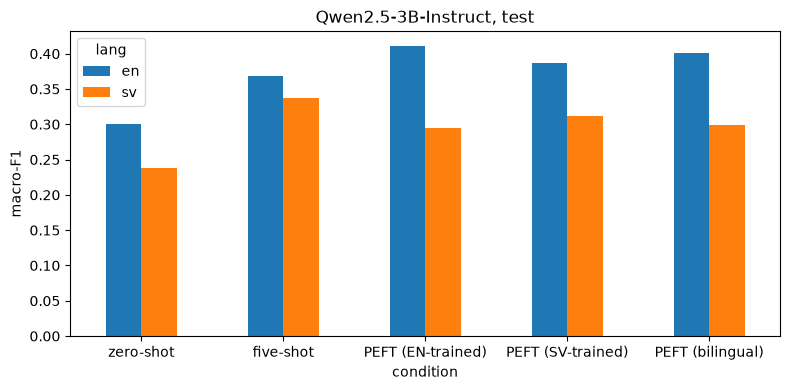

In [3]:
rows = []
for l, c in available:
    m = try_load_metrics(l, c)
    rows.append(
        {
            "lang": l,
            "condition": c,
            "macro_f1": m["macro_f1"],
            "micro_f1": m["micro_f1"],
            "samples_f1": m["samples_f1"],
            "jaccard": m["jaccard"],
            "exact_match": m["exact_match"],
            "malformed": m["malformed_rate"],
            "empty": m["empty_prediction_rate"],
            "labels/text": m["pred_label_cardinality"],
            "gold labels/text": m["gold_label_cardinality"],
        }
    )
main = pd.DataFrame(rows)
order = {c: i for i, c in enumerate(CONDITIONS)}
main = main.sort_values(
    ["lang", "condition"], key=lambda s: s.map(order) if s.name == "condition" else s
)
display(main.set_index(["lang", "condition"]))

ax = (
    main.pivot(index="condition", columns="lang", values="macro_f1")
    .reindex(list(CONDITIONS))
    .plot.bar(rot=0, figsize=(8, 4))
)
ax.set_ylabel("macro-F1")
ax.set_title(f"Qwen2.5-3B-Instruct, {SPLIT}")
plt.tight_layout()
plt.show()

## 3. Paired bootstrap

1,000 resamples of the texts; both conditions are scored on the *same* resampled texts (matched by
alignment ID). If the 95% interval excludes 0, the difference is unlikely to be noise.
The cross-lingual rows compare English and Swedish versions of the same aligned texts.

In [4]:
from llm_project.notebook_utils import binarise, f1s, paired_bootstrap

comparisons = []
for l in LANGS:
    for peft in ["PEFT (EN-trained)", "PEFT (SV-trained)", "PEFT (bilingual)"]:
        for base in ["zero-shot", "five-shot"]:
            comparisons.append((f"{peft} vs {base}", (l, base), (l, peft)))
comparisons += [
    ("SV-trained vs EN-trained (on SV)", ("sv", "PEFT (EN-trained)"), ("sv", "PEFT (SV-trained)")),
    ("bilingual vs EN-trained (on SV)", ("sv", "PEFT (EN-trained)"), ("sv", "PEFT (bilingual)")),
    ("bilingual vs SV-trained (on SV)", ("sv", "PEFT (SV-trained)"), ("sv", "PEFT (bilingual)")),
    ("bilingual vs EN-trained (on EN)", ("en", "PEFT (EN-trained)"), ("en", "PEFT (bilingual)")),
]
for c in CONDITIONS:
    comparisons.append((f"SV vs EN | {c}", ("en", c), ("sv", c)))

rows = []
for name, a, b in comparisons:
    if a not in available or b not in available:
        continue
    d, lo, hi, n = paired_bootstrap(available[a], available[b], labels=LABELS)
    rows.append(
        {
            "comparison": name,
            "lang (A -> B)": f"{a[0]} -> {b[0]}",
            "macro_f1 diff (B-A)": d,
            "ci_low": lo,
            "ci_high": hi,
            "significant": not (lo <= 0 <= hi),
            "n": n,
        }
    )
boot = pd.DataFrame(rows)
boot

,comparison,lang (A -> B),macro_f1 diff (B-A),ci_low,ci_high,significant,n
0,PEFT (EN-trained) vs zero-shot,en -> en,0.112,0.057,0.167,True,250
1,PEFT (EN-trained) vs five-shot,en -> en,0.043,-0.009,0.094,False,250
2,PEFT (SV-trained) vs zero-shot,en -> en,0.086,0.032,0.139,True,250
3,PEFT (SV-trained) vs five-shot,en -> en,0.017,-0.037,0.071,False,250
4,PEFT (bilingual) vs zero-shot,en -> en,0.102,0.047,0.158,True,250
5,PEFT (bilingual) vs five-shot,en -> en,0.033,-0.020,0.083,False,250
6,PEFT (EN-trained) vs zero-shot,sv -> sv,0.056,-0.006,0.120,False,250
7,PEFT (EN-trained) vs five-shot,sv -> sv,-0.042,-0.099,0.015,False,250
8,PEFT (SV-trained) vs zero-shot,sv -> sv,0.074,0.010,0.137,True,250
9,PEFT (SV-trained) vs five-shot,sv -> sv,-0.025,-0.080,0.032,False,250


## 4. Per-emotion F1
Which emotions does fine-tuning improve, and which transfer from English to Swedish?

en                                                \
             zero-shot five-shot PEFT (EN-trained) PEFT (SV-trained)   
anger            0.306     0.459             0.549             0.522   
anticipation     0.411     0.424             0.576             0.527   
disgust          0.245     0.292             0.286             0.333   
fear             0.158     0.400             0.367             0.407   
joy              0.213     0.355             0.375             0.367   
sadness          0.472     0.500             0.528             0.431   
surprise         0.230     0.044             0.290             0.226   
trust            0.364     0.478             0.321             0.276   

                                     sv                              \
             PEFT (bilingual) zero-shot five-shot PEFT (EN-trained)   
anger                   0.573     0.194     0.389             0.457   
anticipation            0.552     0.281     0.468             0.330   
disgust                 0.306     0.054     0.316             0.108   
fear                    0.353     0.103     0.111             0.280   
joy                     0.379     0.292     0.353             0.333   
sadness                 0.448     0.415     0.441             0.429   
surprise                0.286     0.220     0.160             0.203   
trust                   0.316     0.346     0.455             0.214   

                                                gold_support_sv  
             PEFT (SV-trained) PEFT (bilingual)                  
anger                    0.463            0.446              62  
anticipation             0.458            0.456              59  
disgust                  0.185            0.209              34  
fear                     0.304            0.280              34  
joy                      0.286            0.230              38  
sadness                  0.459            0.471              44  
surprise                 0.077            0.041              42  
trust                    0.264            0.264              43

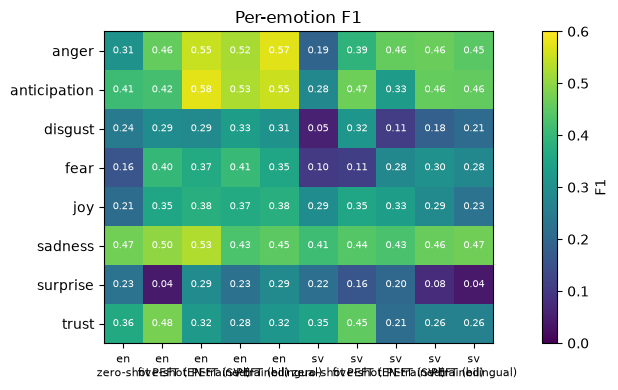

In [5]:
per = {}
for l, c in available:
    m = try_load_metrics(l, c)
    per[(l, c)] = {e: m["per_label"][e]["f1"] for e in LABELS}
per = pd.DataFrame(per)[[k for l in LANGS for k in [(l, c) for c in CONDITIONS] if k in available]]
first = next(iter(available))
per["gold_support_sv"] = (
    [try_load_metrics("sv", "zero-shot")["per_label"][e]["support"] for e in LABELS]
    if ("sv", "zero-shot") in available
    else np.nan
)
display(per)

f1_only = per.drop(columns="gold_support_sv")
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(f1_only.values, cmap="viridis", vmin=0, vmax=max(0.6, np.nanmax(f1_only.values)))
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xticks(range(f1_only.shape[1]), [f"{l}\n{c}" for l, c in f1_only.columns], fontsize=8)
for i in range(f1_only.shape[0]):
    for j in range(f1_only.shape[1]):
        ax.text(j, i, f"{f1_only.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im, label="F1")
ax.set_title("Per-emotion F1")
plt.tight_layout()
plt.show()

## 5. Label counts and label distribution
How often each emotion is predicted, against how often it is gold.

In [6]:
for l in LANGS:
    runs = {c: available[(l, c)] for c in CONDITIONS if (l, c) in available}
    if not runs:
        continue
    gold = next(iter(runs.values()))["gold"]
    table = {
        "GOLD": pd.Series([e for g in gold for e in g]).value_counts().reindex(LABELS, fill_value=0)
    }
    for c, df in runs.items():
        table[c] = (
            pd.Series([e for p in df["pred"] for e in p])
            .value_counts()
            .reindex(LABELS, fill_value=0)
        )
    print(f"--- {l}: predicted counts per emotion ---")
    display(pd.DataFrame(table))

--- en: predicted counts per emotion ---


,GOLD,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained),PEFT (bilingual)
anger,62,23,47,91,72,81
anticipation,59,87,125,73,108,75
disgust,34,15,62,29,44,38
fear,34,4,16,15,20,17
joy,38,9,24,26,22,20
sadness,44,45,28,28,21,23
surprise,42,19,3,20,20,21
trust,43,34,70,13,15,14


--- sv: predicted counts per emotion ---


,GOLD,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained),PEFT (bilingual)
anger,62,10,51,78,98,86
anticipation,59,55,99,44,85,90
disgust,34,3,61,3,31,33
fear,34,5,2,16,12,16
joy,38,10,30,46,32,23
sadness,44,38,24,40,30,24
surprise,42,40,8,17,10,7
trust,43,38,45,13,10,10


## 6. Hard texts: wrong for every condition
Texts that no condition gets exactly right are often texts without an emotional cue (context lost from the film).

In [7]:
for l in LANGS:
    runs = {c: available[(l, c)] for c in CONDITIONS if (l, c) in available}
    if len(runs) < 2:
        continue
    ids = next(iter(runs.values())).index
    exact = pd.DataFrame(
        {
            c: [set(df.at[i, "gold"]) == set(df.at[i, "pred"]) for i in ids]
            for c, df in runs.items()
        },
        index=ids,
    )
    print(f"--- {l}: texts exactly right per number of conditions ---")
    print(exact.sum(axis=1).value_counts().sort_index().to_string())
    hard = exact.index[~exact.any(axis=1)]
    print(f"{len(hard)} of {len(ids)} texts are wrong in every condition. Sample:")
    first_df = next(iter(runs.values()))
    with pd.option_context("display.max_colwidth", 90):
        display(
            first_df.loc[hard[:10], ["text", "gold"]].assign(
                **{c: runs[c].loc[hard[:10], "pred"] for c in runs}
            )
        )

--- en: texts exactly right per number of conditions ---
0    157
1     25
2     17
3     19
4     18
5     14
157 of 250 texts are wrong in every condition. Sample:


,text,gold,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained),PEFT (bilingual)
alignment_id,,,,,,,
en/1954/46754/6980377.xml.gz#1124,She'll never make another picture.,"[anger, sadness]","[anticipation, sadness]","[anticipation, disgust]","[anger, disgust]","[anger, disgust]","[anger, disgust]"
en/1954/46754/6980377.xml.gz#1173,Some things you just don't tell anybody.,"[anger, disgust, fear, sadness]","[anticipation, trust]","[anticipation, trust]",[sadness],[anticipation],[trust]
en/1954/46754/6980377.xml.gz#192,Did you not once direct Jean Harlow and Carole Lombard?,"[anticipation, surprise]",[],[anticipation],[surprise],[surprise],[surprise]
en/1954/46754/6980377.xml.gz#405,Script girl.,[surprise],[],[],[anger],[anticipation],[disgust]
en/1954/46754/6980377.xml.gz#456,"In the dirt, it's hard to tell.",[anticipation],[sadness],[disgust],[sadness],[surprise],[sadness]
en/1954/46754/6980377.xml.gz#509,"I was, up to the minute I saw this test.",[anger],[anticipation],[anticipation],[surprise],[anticipation],[surprise]
en/1954/46754/6980377.xml.gz#751,Neither the picture nor her career mean as much to her as being with her father in his...,"[sadness, trust]",[sadness],[sadness],[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#785,You're beginning to realize maybe the public knows more about public relations than yo...,[joy],[surprise],[anticipation],[anger],"[anger, disgust]","[anger, disgust]"
en/1954/46754/6980377.xml.gz#82,"The fact that you don't drink at all, Kirk, is the greatest argument for drunkenness I...","[anger, anticipation, joy]",[trust],[disgust],"[anger, disgust]","[anger, disgust]","[anger, disgust]"


--- sv: texts exactly right per number of conditions ---
0    151
1     35
2     20
3     22
4     12
5     10
151 of 250 texts are wrong in every condition. Sample:


,text,gold,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained),PEFT (bilingual)
alignment_id,,,,,,,
en/1954/46754/6980377.xml.gz#1124,- Hon har spelat i sin sista film.,"[anger, sadness]",[],"[joy, sadness]",[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#1173,Det finns saker man aldrig berättar.,"[anger, disgust, fear, sadness]",[sadness],"[disgust, sadness]",[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#192,Regisserade inte ni Jean Harlow och Carole Lombard?,"[anticipation, surprise]",[surprise],[anticipation],[surprise],[surprise],[surprise]
en/1954/46754/6980377.xml.gz#405,- Hon är skripta.,[surprise],[],[disgust],[anger],[anger],[anger]
en/1954/46754/6980377.xml.gz#456,- I smutsen är det svart att se hur.,[anticipation],[disgust],[disgust],[sadness],[sadness],[disgust]
en/1954/46754/6980377.xml.gz#50,"Kanske kunde hon dansa en gang till, bara för ikväll.","[anticipation, joy]",[anticipation],"[anticipation, sadness]",[anticipation],[anticipation],[anticipation]
en/1954/46754/6980377.xml.gz#509,"Jag var det, tills jag sag filmen.",[anger],[],"[anticipation, joy]",[joy],[anticipation],[anticipation]
en/1954/46754/6980377.xml.gz#785,Sen inser du att allmänheten kanske förstar mer om reklam än du själv gör.,[joy],[trust],[disgust],[anger],[anger],[anger]
en/1954/46754/6980377.xml.gz#82,"Att du inte dricker alls, Kirk är det bästa argumentet för dryckenskap som jag vet.","[anger, anticipation, joy]",[trust],[disgust],[anger],"[anger, disgust]","[anger, disgust]"


## 7. Swedish texts without å/ä/ö
Some subtitles lost their diacritics (e.g. *grata* for *gråta*). Does that hurt accuracy?

In [8]:
if ("sv", "zero-shot") in available:
    sv_text = available[("sv", "zero-shot")]["text"]
    no_diacritics = ~sv_text.str.lower().str.contains("[åäö]")
    print(
        f"{no_diacritics.sum()} of {len(sv_text)} Swedish texts contain no å/ä/ö "
        "(includes texts that simply don't need them)"
    )
    rows = []
    for c in CONDITIONS:
        if ("sv", c) not in available:
            continue
        df = available[("sv", c)]
        for flag, label in [(no_diacritics, "no å/ä/ö"), (~no_diacritics, "has å/ä/ö")]:
            sub = df[flag.reindex(df.index).values]
            rows.append(
                {
                    "condition": c,
                    "group": label,
                    "n": len(sub),
                    "macro_f1": f1s(binarise(sub["gold"], LABELS), binarise(sub["pred"], LABELS))[0],                }
            )
    display(pd.DataFrame(rows).pivot(index="condition", columns="group", values="macro_f1"))
    with pd.option_context("display.max_colwidth", 90):
        display(sv_text[no_diacritics].head(20).to_frame())

58 of 250 Swedish texts contain no å/ä/ö (includes texts that simply don't need them)


group,has å/ä/ö,no å/ä/ö
condition,,
PEFT (EN-trained),0.302,0.243
PEFT (SV-trained),0.329,0.212
PEFT (bilingual),0.317,0.222
five-shot,0.344,0.304
zero-shot,0.235,0.233


,text
alignment_id,
en/1954/46754/6980377.xml.gz#1124,- Hon har spelat i sin sista film.
en/1954/46754/6980377.xml.gz#1845,- Kan ni nagon spanska?
en/1954/46754/6980377.xml.gz#192,Regisserade inte ni Jean Harlow och Carole Lombard?
en/1954/46754/6980377.xml.gz#270,- Jag tycker inte om min mor.
en/1954/46754/6980377.xml.gz#509,"Jag var det, tills jag sag filmen."
en/1954/46754/6980377.xml.gz#923,Du har arbetat hart.
en/1954/46816/4245477.xml.gz#1292,"- Hur gick det, Tom?"
en/1954/46816/4245477.xml.gz#151,Det var rackarns bussigt av dig.
en/1954/46816/4245477.xml.gz#485,- Skulle jag inte ta emot min pojke?


In [9]:
from llm_project.notebook_utils import compare_predictions
# test if peft is better/worse than prompting, and if sv-trained is better than en-trained on sv


def compare_examples(lang, peft, base="five-shot", k=10):
    if (lang, peft) not in available or (lang, base) not in available:
        print(f"skip: {lang} / {peft} vs {base} not available")
        return None

    base_df = available[(lang, base)]
    cand_df = available[(lang, peft)]
    english_base = available[("en", base)] if lang != "en" and ("en", base) in available else None
    return compare_predictions(
        base_df,
        cand_df,
        base_name=base,
        candidate_name=peft,
        k=k,
        english_df=english_base,
    )


qual = {}
for lang, peft, base in [
    ("sv", "PEFT (SV-trained)", "five-shot"),
    ("sv", "PEFT (bilingual)", "five-shot"),
    ("en", "PEFT (EN-trained)", "five-shot"),
    ("sv", "PEFT (SV-trained)", "PEFT (EN-trained)"),
]:
    qual[(lang, peft, base)] = compare_examples(lang, peft, base=base)

=== PEFT (SV-trained) vs five-shot | improved 60, worsened 52, same 138 ===
Candidate IMPROVED:


,text,gold,five-shot,PEFT (SV-trained),delta,english_text
alignment_id,,,,,,
en/1954/46754/6980377.xml.gz#1109,Säg at alla att ga.,[anger],[],[anger],1.0,Tell everybody to go home.
en/1954/46754/6980377.xml.gz#36,"Vi sökte efter vad som pa finsprak kallas ""ett nytt ansikte"".",[anticipation],[],[anticipation],1.0,"Well, we'd been scouting for what is called delicately ""a new face."""
en/1965/59037/5735869.xml.gz#1129,"- Ess, kung, tia.",[joy],[],[joy],1.0,"Ace, king, 10."
en/1990/100404/5649520.xml.gz#1122,Sen kommer den materiella bevisningen:,[anticipation],[],[anticipation],1.0,Then come the physical proofs:
en/1965/59309/6919338.xml.gz#1841,- Jag har försökt i timmar.,[anger],"[anticipation, sadness]",[anger],1.0,- Been trying to raise him for hours.
en/1965/59037/5735869.xml.gz#562,Problemet är att Kid kanske är nervös.,[fear],[disgust],[fear],1.0,"Trouble is that the Kid might be nervous, big game like this."
en/1990/100212/6671913.xml.gz#766,Hade ni befogenhet att gå igenom bagaget?,[anger],[disgust],[anger],1.0,Did you have a warrant to search his trunk?
en/1990/100514/3930419.xml.gz#942,Jag sa åt dig att sätta på bilbältet.,[anger],[anticipation],[anger],1.0,I told you to fasten your seat belt.
en/1990/100507/58167.xml.gz#1457,Det är inte Tomten.,[anger],[],[anger],1.0,That ain't Santa.


Candidate WORSENED:


,text,gold,five-shot,PEFT (SV-trained),delta,english_text
alignment_id,,,,,,
en/1954/46754/6980377.xml.gz#1306,Min champagne är inte kall nog.,[disgust],[disgust],[anger],-1.0,My champagne is not properly cooled.
en/1954/46754/6980377.xml.gz#270,- Jag tycker inte om min mor.,[disgust],[disgust],[sadness],-1.0,Because I do not like my mother.
en/1954/46754/6980377.xml.gz#923,Du har arbetat hart.,[trust],[trust],[joy],-1.0,You worked hard.
en/1954/46754/6980377.xml.gz#751,Varken film eller karriär är värt nagot da hon kan vara hos sin far da han b...,"[sadness, trust]","[sadness, trust]","[anger, disgust]",-1.0,Neither the picture nor her career mean as much to her as being with her fat...
en/1954/46816/4245477.xml.gz#1124,- Kan ni upprepa det inför rätta?,[trust],[trust],"[anger, disgust]",-1.0,- Would you repeat it in court?
en/1954/46816/4245477.xml.gz#704,Jag känner till onormalt beteende.,[sadness],[sadness],[fear],-1.0,I know about abnormal behaviour.
en/1990/100212/6671913.xml.gz#1565,-Jag slår inte vad när jag har rätt.,[joy],[joy],"[anger, disgust]",-1.0,-I never bet when I'm sure I'm right.
en/1965/59309/6919338.xml.gz#2115,I ert fall som chef för en hel flottstyrka.,[trust],[trust],"[anticipation, joy]",-1.0,You'll do it from the deck of a ship in command of a task force.
en/1965/59309/6919338.xml.gz#754,Vad flår du för nåt?,[anticipation],[anticipation],[anger],-1.0,What do you skin?


=== PEFT (bilingual) vs five-shot | improved 52, worsened 51, same 147 ===
Candidate IMPROVED:


,text,gold,five-shot,PEFT (bilingual),delta,english_text
alignment_id,,,,,,
en/1954/46754/6980377.xml.gz#710,Nagot rätt sa viktigt har hänt.,[anticipation],[anger],[anticipation],1.0,"I say, something kind of important has come up."
en/1954/46754/6980377.xml.gz#36,"Vi sökte efter vad som pa finsprak kallas ""ett nytt ansikte"".",[anticipation],[],[anticipation],1.0,"Well, we'd been scouting for what is called delicately ""a new face."""
en/1954/46816/4245477.xml.gz#717,- Det Tom säger låter vettigt.,[trust],[disgust],[trust],1.0,- I think Tom does make sense.
en/1965/59037/5735869.xml.gz#1129,"- Ess, kung, tia.",[joy],[],[joy],1.0,"Ace, king, 10."
en/1965/59309/6919338.xml.gz#1841,- Jag har försökt i timmar.,[anger],"[anticipation, sadness]",[anger],1.0,- Been trying to raise him for hours.
en/1990/100404/5649520.xml.gz#1122,Sen kommer den materiella bevisningen:,[anticipation],[],[anticipation],1.0,Then come the physical proofs:
en/1990/100212/6671913.xml.gz#766,Hade ni befogenhet att gå igenom bagaget?,[anger],[disgust],[anger],1.0,Did you have a warrant to search his trunk?
en/1965/59358/185209.xml.gz#112,- Har ni lust att käka med mig?,[anticipation],"[joy, trust]",[anticipation],1.0,I was gonna fix some chow.
en/1965/59037/5735869.xml.gz#562,Problemet är att Kid kanske är nervös.,[fear],[disgust],[fear],1.0,"Trouble is that the Kid might be nervous, big game like this."


... (6 outputs left out)

=== PEFT (SV-trained) vs PEFT (EN-trained) | improved 35, worsened 28, same 187 ===
Candidate IMPROVED:


,text,gold,PEFT (EN-trained),PEFT (SV-trained),delta,english_text
alignment_id,,,,,,
en/1954/46754/6980377.xml.gz#1568,När jag tänker tillbaka var jag nog inte lika orolig da som jag trodde.,[sadness],[joy],[sadness],1.0,"Looking back,"
en/1954/46754/6980377.xml.gz#465,Och ni vill väl säga adjö.,[sadness],[joy],[sadness],1.0,"Then, you'll want to say goodbye."
en/1965/59037/5735869.xml.gz#443,Hon knäcktes i Vegas.,[anger],[surprise],[anger],1.0,She busted out in a Vegas faro game.
en/1965/59309/6919338.xml.gz#1427,Saknar du torpedbåtarna?,[anticipation],[surprise],[anticipation],1.0,Want a transfer back to PT boats?
en/2015/4428184/6361946.xml.gz#404,Men jag är inte säker på att nåt annat stämmer heller.,[fear],[sadness],[fear],1.0,But I'm not sure anything else makes sense right now.
en/2015/4428184/6361946.xml.gz#242,Menar du att hon blev kidnappad?,[surprise],[fear],[surprise],1.0,Are you saying she was kidnapped?
en/2017/6398054/7016299.xml.gz#123,Jag tror inte folk går igenom livet och tänker på barnsexhandel i USA.,[sadness],[anger],[sadness],1.0,I don't think everybody goes through life thinking about child sex trafficki...
en/2012/1822302/6406444.xml.gz#1322,"- Hjälp din mormor en sekund, Fonzie.",[anticipation],[fear],[anticipation],1.0,"Hey Fonzie, come here and help your grandma for a minute."
en/1990/100507/58167.xml.gz#1457,Det är inte Tomten.,[anger],[sadness],[anger],1.0,That ain't Santa.


Candidate WORSENED:


,text,gold,PEFT (EN-trained),PEFT (SV-trained),delta,english_text
alignment_id,,,,,,
en/1954/46754/6980377.xml.gz#1063,"Hall tyst, försvinn dit ni kom ifran.",[anger],[anger],[fear],-1.0,Why don't you shut up and go back where you came from?
en/1965/59113/239628.xml.gz#1770,haft ett hus och barn.,[sadness],[sadness],[joy],-1.0,"We'd have got married, had a house and children."
en/1954/46816/4245477.xml.gz#704,Jag känner till onormalt beteende.,[sadness],[sadness],[fear],-1.0,I know about abnormal behaviour.
en/1954/46816/4245477.xml.gz#1566,Queeg riskerade livet på manskapet.,[fear],[fear],[anger],-1.0,Queeg endangered the lives of the men.
en/1990/100405/4706696.xml.gz#2142,Ni anländer till New York när ni ska.,[anticipation],[anticipation],[anger],-1.0,You should be back in New York on time.
en/1965/59358/185209.xml.gz#940,- Det är jag som ska döda hunden.,[anger],[anger],[sadness],-1.0,"The dog's mine to kill, an eye for an eye."
en/2015/4434386/6058767.xml.gz#49,Ingen idiot?,[surprise],[surprise],[anger],-1.0,"I told you I didn't do anything illegal, and I didn't."
en/1990/100507/58167.xml.gz#340,Varför inte knyta upp fler matcher?,[anticipation],[anticipation],[anger],-1.0,Why not a couple more fights?
en/2015/4428472/6156726.xml.gz#505,Det var förhoppningen.,[joy],[joy],[anticipation],-1.0,That was the hope.
